## CL-1 Lab Assignment 3 (Group A) : Classification Analysis
### Handwritten Digit Recognition using Support Vector Machines (SVM)

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits
from sklearn.model_selection import (train_test_split, cross_val_score, GridSearchCV, StratifiedKFold)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
digits = load_digits()
X, y = digits.data, digits.target

print("Feature matrix shape :", X.shape)
print("Target vector shape  :", y.shape)
print("Image array shape    :", digits.images.shape)
print("Classes              :", np.unique(y))
print("Pixel value range    :", X.min(), "to", X.max())

Feature matrix shape : (1797, 64)
Target vector shape  : (1797,)
Image array shape    : (1797, 8, 8)
Classes              : [0 1 2 3 4 5 6 7 8 9]
Pixel value range    : 0.0 to 16.0


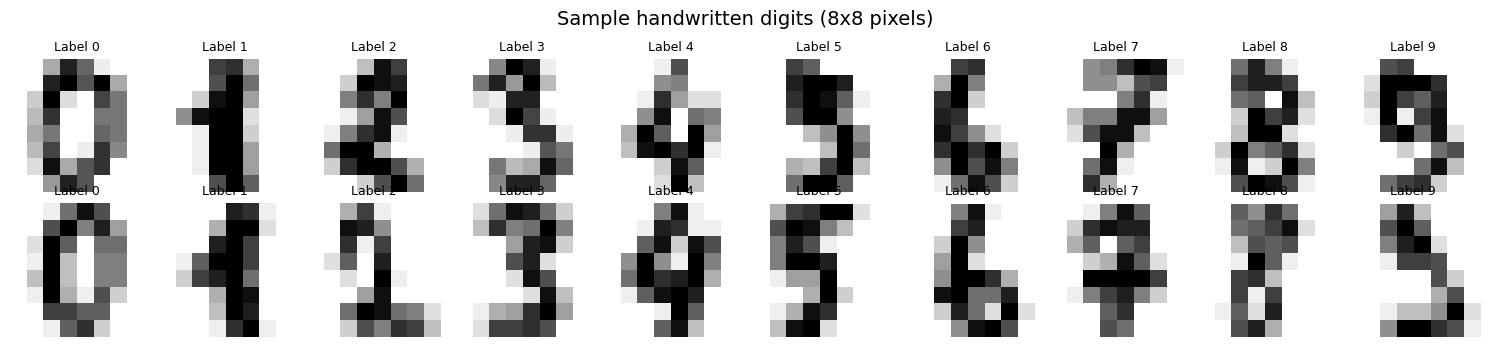

In [3]:
# Sample images from every class
fig, axes = plt.subplots(2, 10, figsize=(15, 3.5))
for digit, ax_col in zip(range(10), axes.T):
    idx = np.where(y == digit)[0][:2]
    for i, ax in zip(idx, ax_col):
        ax.imshow(digits.images[i], cmap="gray_r")
        ax.set_title(f"Label {digit}", fontsize=9)
        ax.axis("off")
plt.suptitle("Sample handwritten digits (8x8 pixels)", fontsize=14)
plt.tight_layout()
plt.show()

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=45)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train class share (%):", np.round(np.bincount(y_train) / len(y_train) * 100, 1))
print("Test  class share (%):", np.round(np.bincount(y_test)  / len(y_test)  * 100, 1))

Train: (1437, 64)  Test: (360, 64)
Train class share (%): [ 9.9 10.1  9.9 10.2 10.1 10.2 10.1 10.   9.7 10. ]
Test  class share (%): [10.  10.3  9.7 10.3 10.  10.  10.  10.   9.7 10. ]


In [5]:
baseline = Pipeline([("scaler", StandardScaler()),
                     ("svm", SVC(kernel="rbf", C=1.0, gamma="scale"))])

t0 = time.time()
baseline.fit(X_train, y_train)
fit_time = time.time() - t0

y_pred_base = baseline.predict(X_test)
print(f"Training time : {fit_time:.3f} s")
print(f"Test accuracy : {accuracy_score(y_test, y_pred_base):.4f}")
print(f"Support vectors used: {baseline.named_steps['svm'].n_support_.sum()} of {len(X_train)} training samples")

Training time : 0.105 s
Test accuracy : 0.9806
Support vectors used: 720 of 1437 training samples


In [6]:
kernels = {"linear": SVC(kernel="linear", C=1),
           "poly (deg=3)": SVC(kernel="poly", degree=3, C=1, gamma="scale"),
           "rbf": SVC(kernel="rbf", C=1, gamma="scale"),
           "sigmoid": SVC(kernel="sigmoid", C=1, gamma="scale")}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=45)
rows = []
for name, model in kernels.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("svm", model)])
    cv = cross_val_score(pipe, X_train, y_train, cv=skf)
    t0 = time.time(); pipe.fit(X_train, y_train); tt = time.time() - t0
    pred = pipe.predict(X_test)
    rows.append({"Kernel": name, "CV mean acc": cv.mean(), "CV std": cv.std(),
                 "Test acc": accuracy_score(y_test, pred),
                 "Test F1 (macro)": f1_score(y_test, pred, average="macro"),
                 "Train time (s)": tt})
kernel_df = pd.DataFrame(rows).set_index("Kernel").round(4)
kernel_df

,CV mean acc,CV std,Test acc,Test F1 (macro),Train time (s)
Kernel,,,,,
linear,0.9742,0.0100,0.9806,0.9805,0.0547
poly (deg=3),0.9534,0.0134,0.9500,0.9518,0.1076
rbf,0.9791,0.0129,0.9806,0.9806,0.1059
sigmoid,0.9506,0.0118,0.9361,0.9364,0.0792


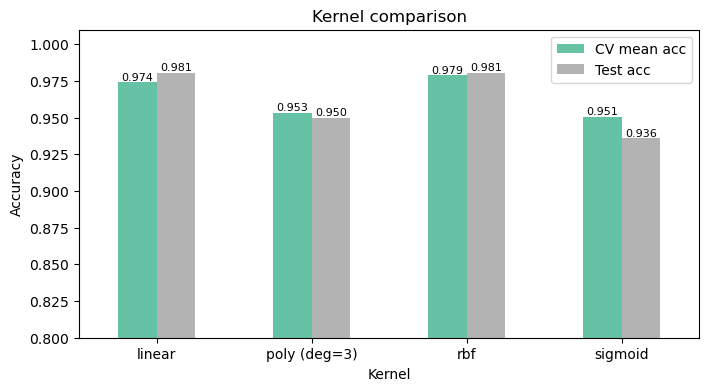

In [7]:
ax = kernel_df[["CV mean acc", "Test acc"]].plot(kind="bar", figsize=(8, 4), rot=0, colormap="Set2")
ax.set_ylim(0.8, 1.01); ax.set_ylabel("Accuracy"); ax.set_title("Kernel comparison")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom", fontsize=8)
plt.show()

**Observation:** With default parameters, RBF gives the best cross-validated accuracy, the linear kernel is very close (digits are almost linearly separable in 64-D), the polynomial kernel is a little less stable (higher CV std) and the sigmoid kernel is clearly the weakest. Default parameters are not optimal, though - see the tuning step below, where the polynomial kernel becomes the best after tuning `C`.

In [8]:
pipe = Pipeline([("scaler", StandardScaler()), ("svm", SVC())])

param_grid = [
    {"svm__kernel": ["rbf"],  "svm__C": [0.1, 1, 10, 100], "svm__gamma": [0.0001, 0.001, 0.01, 0.1]},
    {"svm__kernel": ["poly"], "svm__C": [0.1, 1, 10],      "svm__degree": [2, 3, 4], "svm__gamma": ["scale"]},
    {"svm__kernel": ["linear"], "svm__C": [0.01, 0.1, 1, 10]},
]
grid = GridSearchCV(pipe, param_grid, cv=skf, scoring="accuracy", n_jobs=-1, return_train_score=True)

t0 = time.time()
grid.fit(X_train, y_train)
print(f"Grid search finished in {time.time() - t0:.1f}s over {len(grid.cv_results_['params'])} candidates")
print("Best parameters :", grid.best_params_)
print(f"Best CV accuracy: {grid.best_score_:.4f}")

Grid search finished in 49.1s over 29 candidates
Best parameters : {'svm__C': 10, 'svm__degree': 3, 'svm__gamma': 'scale', 'svm__kernel': 'poly'}
Best CV accuracy: 0.9840


In [9]:
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

print(f"Test accuracy   : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision (macro): {precision_score(y_test, y_pred, average='macro'):.4f}")
print(f"Recall    (macro): {recall_score(y_test, y_pred, average='macro'):.4f}")
print(f"F1-score  (macro): {f1_score(y_test, y_pred, average='macro'):.4f}")
print()
print(classification_report(y_test, y_pred, digits=3))


Test accuracy   : 0.9833
Precision (macro): 0.9836
Recall    (macro): 0.9836
F1-score  (macro): 0.9833

              precision    recall  f1-score   support

           0      1.000     1.000     1.000        36
           1      1.000     0.973     0.986        37
           2      0.972     1.000     0.986        35
           3      1.000     0.946     0.972        37
           4      1.000     1.000     1.000        36
           5      0.971     0.944     0.958        36
           6      1.000     1.000     1.000        36
           7      1.000     1.000     1.000        36
           8      0.946     1.000     0.972        35
           9      0.946     0.972     0.959        36

    accuracy                          0.983       360
   macro avg      0.984     0.984     0.983       360
weighted avg      0.984     0.983     0.983       360



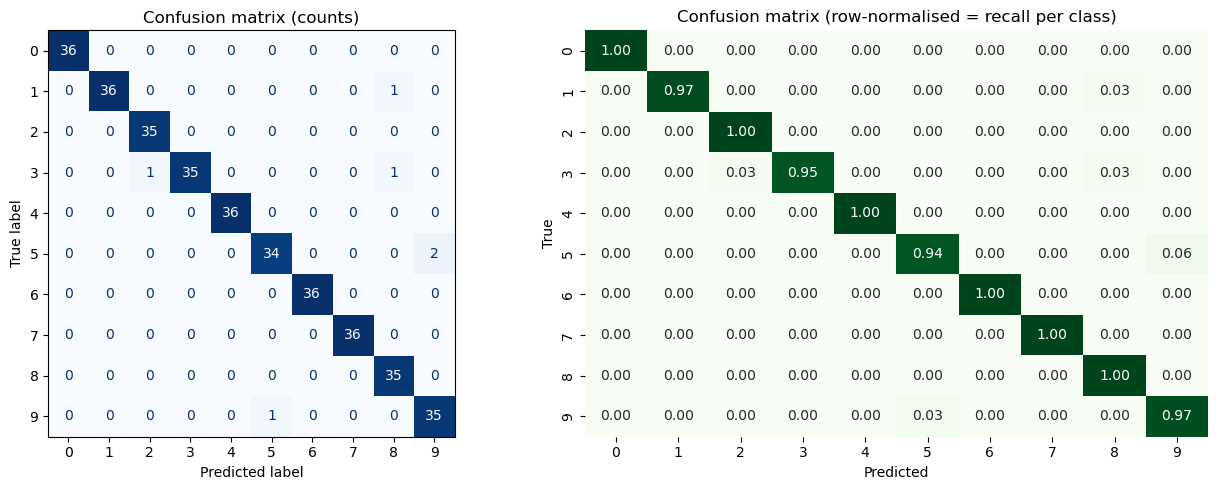

In [10]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Confusion matrix (counts)")
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Greens", ax=ax[1], cbar=False)
ax[1].set_title("Confusion matrix (row-normalised = recall per class)")
ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("True")
plt.tight_layout(); plt.show()

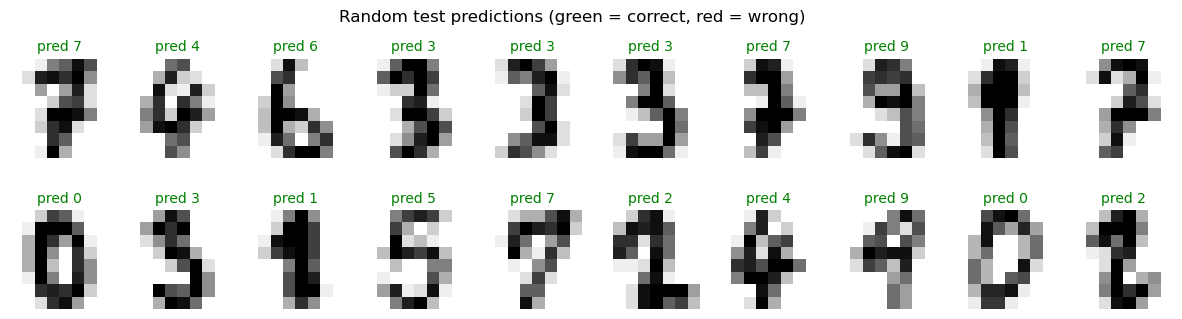

In [26]:
# A random sample of correct + incorrect predictions
rng = np.random.RandomState(0)
idx = rng.choice(len(y_test), 20, replace=False)
fig, axes = plt.subplots(2, 10, figsize=(15, 3.6))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(X_test[i].reshape(8, 8), cmap="gray_r"); ax.axis("off")
    ok = y_pred[i] == y_test[i]
    ax.set_title(f"pred {y_pred[i]}", color="green" if ok else "red", fontsize=10)
plt.suptitle("Random test predictions (green = correct, red = wrong)")
plt.show()